# **Sales Prediction Using Python**

**Objective:** Build a machine learning model that predicts product sales from advertising spend on TV, Radio and Newspaper, and identify which channel has the greatest impact on sales.

**Tech Stack:** Python, pandas, scikit-learn, matplotlib/seaborn, Google Colab

**Dataset:** Advertising Budget and Sales dataset: 200 markets, 3 advertising budgets (TV, Radio, Newspaper) and the resulting Sales.

**Problem type:** Regression (predicting a number, not a category).

**Author:** Hanifah Morayo Abdulazeez

# **IMPORTS**

In [1]:
 # Data handling and visualisation imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling Imports
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# **Load Data**
The dataset file (`Advertising Budget and Sales.csv`) must be uploaded to the Colab session before running the next cell to access the CSV data.

In [2]:
# Read file directly from Colab session storage
df = pd.read_csv('/content/Advertising Budget and Sales.csv')


In [3]:

# # Dropped the extra index column if present.
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

In [4]:
# Rename columns to clean and simple names
df.columns = ['TV', 'Radio', 'Newspaper', 'Sales']

# Display the first 10 rows of data
df.head(10)

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6


**Units:** TV, Radio and Newspaper are advertising budgets in thousands of dollars, and Sales is sales revenue in millions of dollars.

# **EXPLORATORY DATA ANALYSIS**


In [5]:
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
df.describe()

Shape: 200 rows, 4 columns
Missing values: 0
Duplicate rows: 0

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Descriptive statistics:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


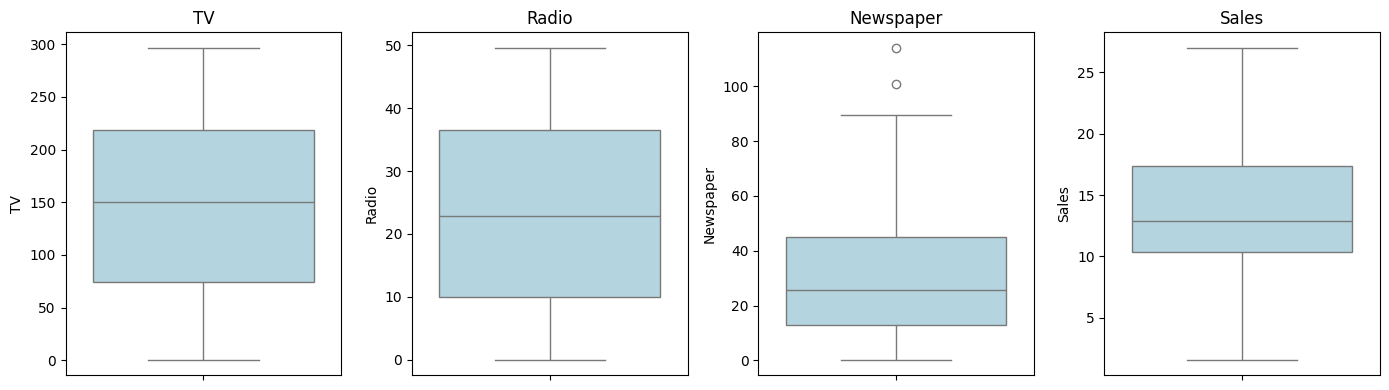

In [6]:
# Box plots to check for outliers
plt.figure(figsize=(14, 4))
for i, col in enumerate(df.columns):
    plt.subplot(1, 4, i + 1)
    sns.boxplot(y=df[col], color='lightblue')
    plt.title(col)
plt.tight_layout()
plt.show()

**Findings from the data check:**
- 200 rows and 4 columns, all numeric.
- No missing values and no duplicate rows.
- Newspaper has 2 high-spend outliers (up to 114). They were kept because they are real budget values, not errors.

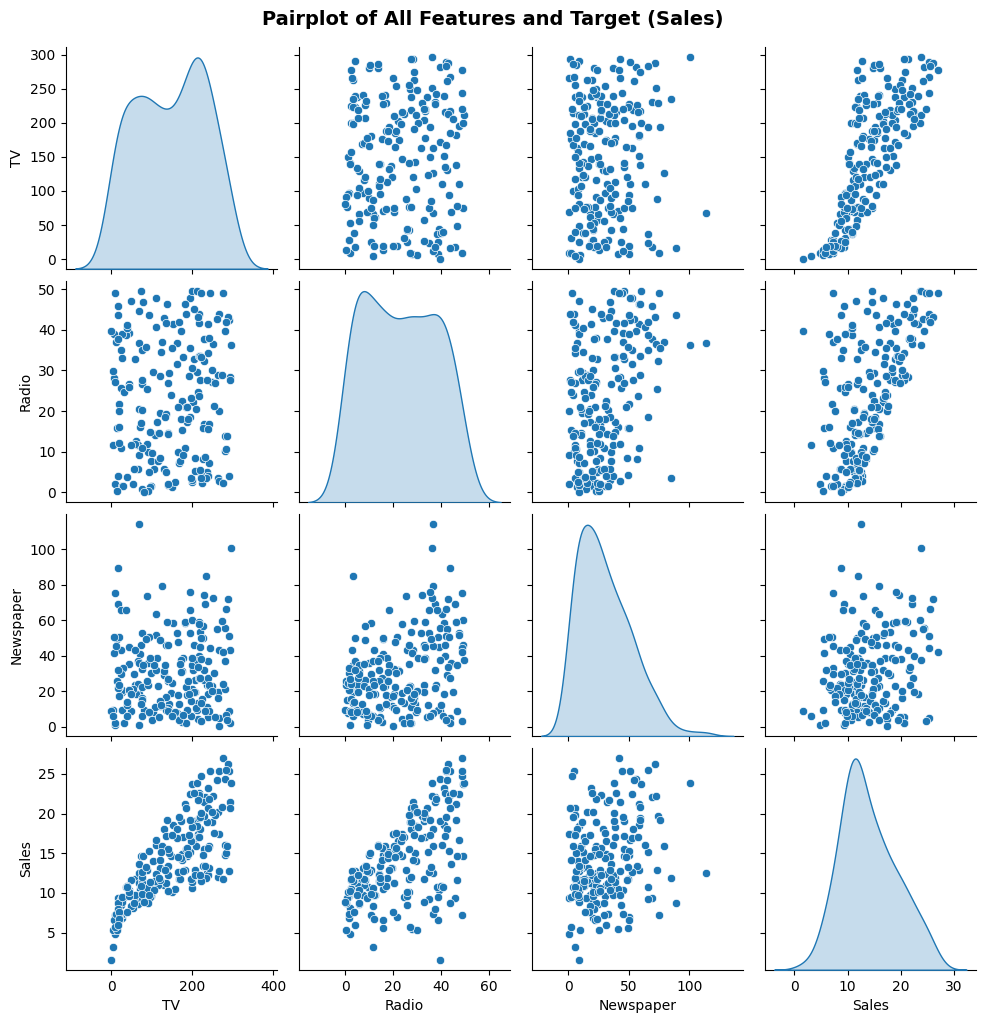

In [7]:
# Pairplot of all features (TV, Radio, Newspaper, Sales)
sns.pairplot(df, diag_kind='kde')
plt.suptitle("Pairplot of All Features and Target (Sales)", y=1.02, fontsize=14, fontweight='bold')
plt.show()

**What the pairplot shows:**

The pairplot compares every column with every other column in one grid. The scatter plots show how two columns relate, and the curves on the diagonal show how the values of a single column are spread out (the taller the curve, the more markets have values there).

**Reading the Sales row (the most important one):**
- **TV vs Sales:** The dots rise steadily from bottom left to top right in a fairly tight band. Markets that spend more on TV tend to make clearly higher sales.
- **Radio vs Sales:** The dots also rise, but they are more spread out. Radio spend helps predict sales, but less reliably than TV.
- **Newspaper vs Sales:** The dots form a loose cloud with almost no upward trend. Newspaper spend tells us very little about sales.

**Reading the diagonal (how each column is spread out):**
- **TV and Radio:** Spending is spread fairly evenly across markets, with no single typical budget.
- **Newspaper:** Most markets spend a small amount, and only a few spend much more (up to 114 thousand dollars). These are the high-spend outliers seen earlier.
- **Sales:** Most markets make between about 10 and 17 million dollars, with only a few at the very low or very high ends.

**Between the advertising channels:** The scatter plots for TV, Radio and Newspaper against each other show no clear pattern, apart from a slight upward tendency between Radio and Newspaper. This means each channel brings its own information, and the channels are not just copies of one another.

**Overall:** TV has the clearest link with Sales, Radio comes second, and Newspaper is the weakest. The correlation heatmap below puts exact numbers on this.

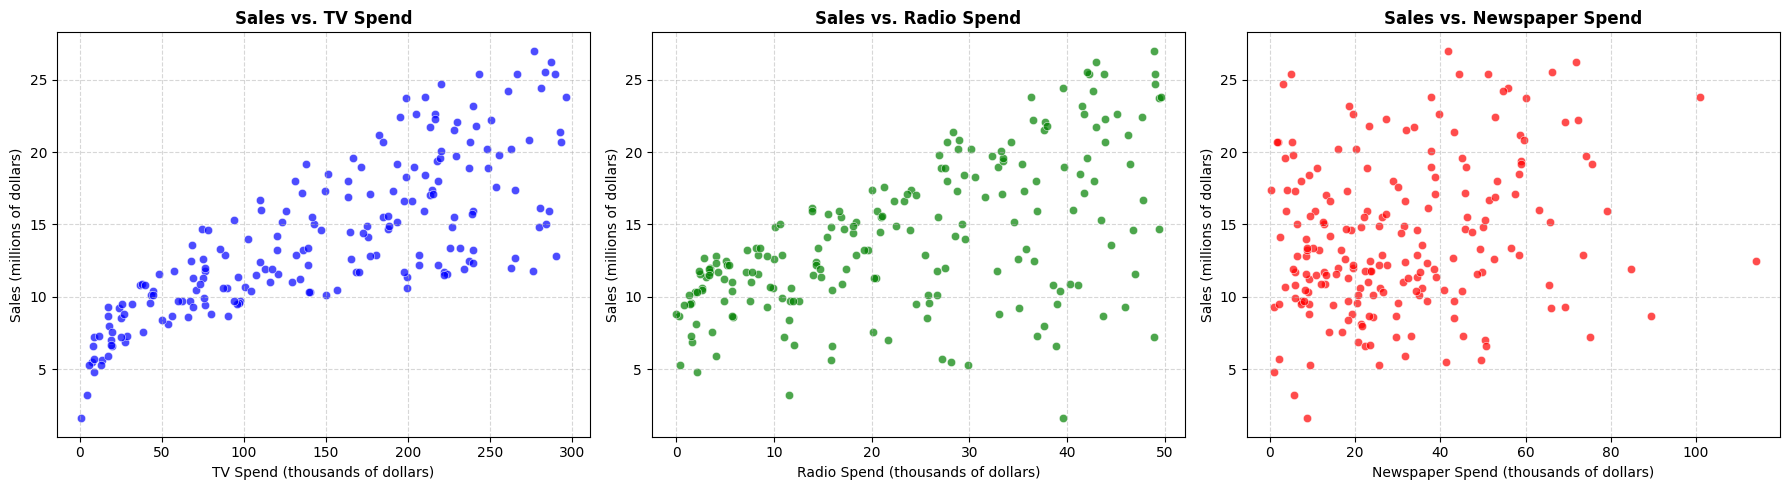

In [8]:
# Create a 1x3 grid for individual scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Sales vs TV Spend
sns.scatterplot(ax=axes[0], x='TV', y='Sales', data=df, color='blue', alpha=0.7)
axes[0].set_title('Sales vs. TV Spend', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TV Spend (thousands of dollars)', fontsize=10)
axes[0].set_ylabel('Sales (millions of dollars)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Sales vs Radio Spend
sns.scatterplot(ax=axes[1], x='Radio', y='Sales', data=df, color='green', alpha=0.7)
axes[1].set_title('Sales vs. Radio Spend', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Radio Spend (thousands of dollars)', fontsize=10)
axes[1].set_ylabel('Sales (millions of dollars)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)

# Sales vs Newspaper Spend
sns.scatterplot(ax=axes[2], x='Newspaper', y='Sales', data=df, color='red', alpha=0.7)
axes[2].set_title('Sales vs. Newspaper Spend', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Newspaper Spend (thousands of dollars)', fontsize=10)
axes[2].set_ylabel('Sales (millions of dollars)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**What the scatter plots show:**

- **TV:** Markets that spend more on TV advertising tend to make higher sales, and this pattern is clear and consistent.
- **Radio:** Markets that spend more on Radio advertising also tend to make higher sales, but the pattern is less consistent than TV, because some markets with similar Radio spend have very different sales.
- **Newspaper:** Spending more on Newspaper advertising shows almost no clear effect on sales, because markets with low and high Newspaper spend have similar sales.

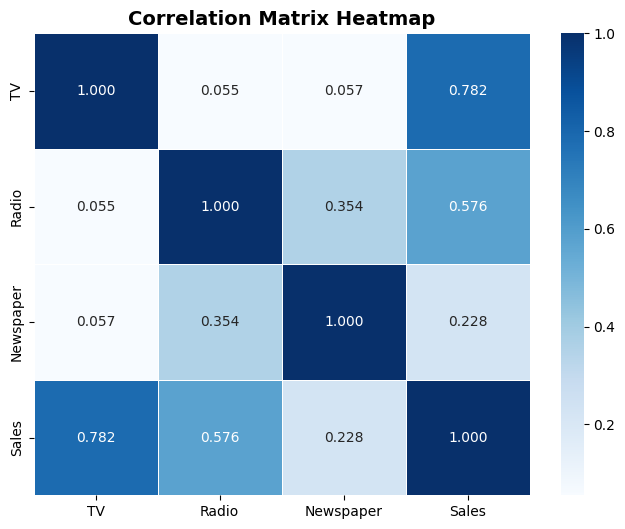

In [9]:
# Compute correlation matrix
corr_matrix = df.corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap', fontsize=14, fontweight='bold')
plt.show()

**What the correlation heatmap shows:**

- **TV:** Has the strongest link with Sales (0.78). Markets that spend more on TV advertising tend to make clearly higher sales.
- **Radio:** Has a moderate link with Sales (0.58). Higher Radio spend also goes with higher sales, but less strongly than TV.
- **Newspaper:** Has a weak link with Sales (0.23). Newspaper spend tells us very little about how much a market will sell.
- **Between the channels:** TV spend is almost unrelated to Radio and Newspaper spend (about 0.06), so each one adds its own information. Radio and Newspaper are somewhat related (0.35), meaning markets that spend more on Radio also tend to spend more on Newspaper. This is likely why Newspaper looks slightly useful on its own, even though its real effect is small.
- **Important:** A strong correlation shows that two things move together, not that one causes the other.

# **Train/Test Split**
- 80% of the data (160 markets) trains the model, 20% (40 markets) tests it on data it has never seen.
- `random_state=42` makes the split reproducible.

In [10]:
# Separate features (X) and target variable (y)
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 160 samples
Testing set size: 40 samples


# **Model Training**


In [11]:
# Baseline model: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("--- Baseline Linear Regression Trained ---")
print(f"Intercept (Base Sales): {lr_model.intercept_:.4f}")
for col, coef in zip(X.columns, lr_model.coef_):
    print(f"Coefficient for {col}: {coef:.4f}")

--- Baseline Linear Regression Trained ---
Intercept (Base Sales): 2.9791
Coefficient for TV: 0.0447
Coefficient for Radio: 0.1892
Coefficient for Newspaper: 0.0028


**Note on feature scaling:** The features were not scaled (adjusted to a common range) because it was not needed here. All three budgets are already in the same unit (thousands of dollars), and the two models used, Linear Regression and Random Forest, give the same results whether or not the features are scaled.

# **Additional Model: Random Forest**

Linear Regression assumes sales rise in a straight line with advertising spend. To check whether a more flexible model does better, a Random Forest Regressor was added. It builds many decision trees (100 here, set by `n_estimators=100`) and averages their predictions, which lets it capture curved relationships that Linear Regression cannot. Both models are tested on the same 40 markets so the comparison is fair.

In [12]:
# 1. Train the additional model: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Generate predictions on the test data for both models
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# 3. Calculate evaluation metrics (MAE, RMSE, R²)
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

mae_lr, rmse_lr, r2_lr = compute_metrics(y_test, y_pred_lr)
mae_rf, rmse_rf, r2_rf = compute_metrics(y_test, y_pred_rf)

# 4. Display evaluation results
print("=" * 55)
print("MODEL EVALUATION COMPARISON")
print("=" * 55)
print("Linear Regression Baseline:")
print(f"  - Mean Absolute Error (MAE):      {mae_lr:.4f}")
print(f"  - Root Mean Squared Error (RMSE): {rmse_lr:.4f}")
print(f"  - R² Score:                       {r2_lr:.4f}\n")

print("Random Forest Regressor:")
print(f"  - Mean Absolute Error (MAE):      {mae_rf:.4f}")
print(f"  - Root Mean Squared Error (RMSE): {rmse_rf:.4f}")
print(f"  - R² Score:                       {r2_rf:.4f}")

MODEL EVALUATION COMPARISON
Linear Regression Baseline:
  - Mean Absolute Error (MAE):      1.4608
  - Root Mean Squared Error (RMSE): 1.7816
  - R² Score:                       0.8994

Random Forest Regressor:
  - Mean Absolute Error (MAE):      0.6201
  - Root Mean Squared Error (RMSE): 0.7686
  - R² Score:                       0.9813


# **Model Evaluation**

In [13]:
results_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf],
    'R²': [r2_lr, r2_rf]
}).set_index('Model').round(4)

results_df

,MAE,RMSE,R²
Model,,,
Linear Regression,1.4608,1.7816,0.8994
Random Forest,0.6201,0.7686,0.9813


### How to read the metrics
- **MAE (Mean Absolute Error):** the average size of the model's mistakes, in millions of dollars of sales revenue.
- **RMSE (Root Mean Squared Error):** like MAE but penalises big mistakes more. Lower is better.
- **R²:** the share of the variation in sales the model explains. 1.0 is perfect.

### Results on the test set (40 markets)
- Linear Regression is off by about 1.46 million dollars on average (R² = 0.90).
- Random Forest is off by about 0.62 million dollars on average (R² = 0.98).
- Random Forest has the lower error on every metric.

In [14]:
# 5-fold cross-validation on the full dataset
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

cv_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

cv_results = {}
for name, model in cv_models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=scoring)
    cv_results[name] = {
        'R² (mean)': s['test_r2'].mean(),
        'R² (std)': s['test_r2'].std(),
        'MAE': -s['test_mae'].mean(),
        'RMSE': -s['test_rmse'].mean()
    }

pd.DataFrame(cv_results).T.round(4)

,R² (mean),R² (std),MAE,RMSE
Linear Regression,0.8827,0.0395,1.2873,1.7057
Random Forest,0.9805,0.0050,0.5431,0.7079


**Cross-validation check:** To make sure the result is not due to one lucky split, each model was tested 5 times on different parts of the data. Random Forest again performed better, with an average R² of 0.98 against 0.88 for Linear Regression, and its average error was about 0.54 million dollars against 1.29 million. Random Forest's scores also varied much less between the 5 tests, so its advantage is reliable.

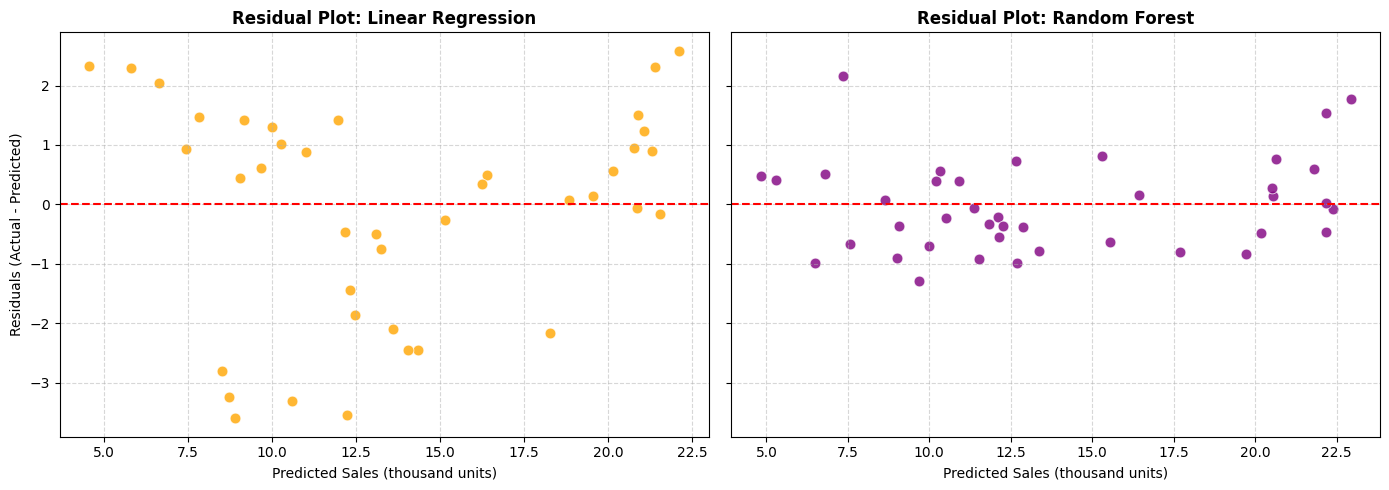

In [15]:
residuals_lr = y_test - y_pred_lr
residuals_rf = y_test - y_pred_rf

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, pred, res, title, color in zip(
        axes, [y_pred_lr, y_pred_rf], [residuals_lr, residuals_rf],
        ['Linear Regression', 'Random Forest'], ['orange', 'purple']):
    sns.scatterplot(x=pred, y=res, color=color, alpha=0.8, s=60, ax=ax)
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    ax.set_title(f'Residual Plot: {title}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Sales (thousand units)')
    ax.grid(True, linestyle='--', alpha=0.5)
axes[0].set_ylabel('Residuals (Actual - Predicted)')
plt.tight_layout()
plt.show()



**What the residual plots show:**

A residual is the difference between the actual sales and the model's predicted sales. Each dot is one market in the test set. A dot on the red line means a perfect prediction, a dot above it means the model predicted too low, and a dot below it means the model predicted too high. A good model has dots scattered randomly around the line, with no pattern.

- **Linear Regression:** The dots form a curve instead of a random scatter. The model predicts too high for markets with mid-range sales (dots below the line) and too low for markets with the highest sales (dots above the line). This tells us the link between advertising spend and sales is not a perfectly straight line, and Linear Regression can only draw straight lines.
- **Random Forest:** The dots are scattered randomly around the line and sit closer to it, with no curve or funnel shape. It handles the curved relationship much better, so its mistakes are smaller and show no pattern.

  Channel  Random Forest Importance  Linear Regression Coef  Permutation Importance
       TV                    0.6248                  0.0447                  1.3811
    Radio                    0.3622                  0.1892                  0.5362
Newspaper                    0.0130                  0.0028                 -0.0004


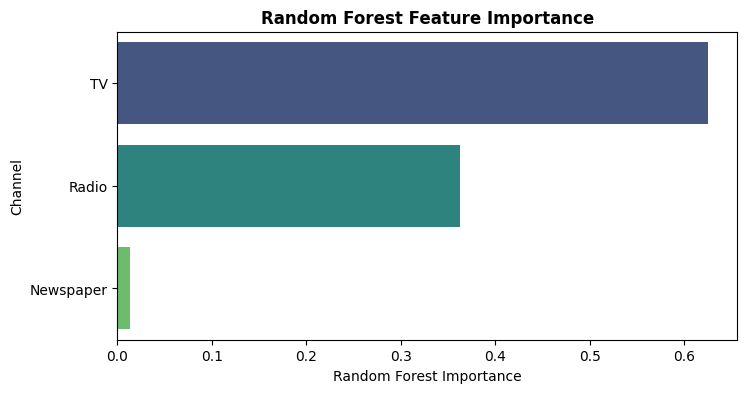

In [16]:
# Feature importance: three views
imp_df = pd.DataFrame({
    'Channel': X.columns,
    'Random Forest Importance': rf_model.feature_importances_,
    'Linear Regression Coef': lr_model.coef_
}).sort_values(by='Random Forest Importance', ascending=False)

# Second check: permutation importance on the test set
perm = permutation_importance(rf_model, X_test, y_test, n_repeats=20, random_state=42)
imp_df['Permutation Importance'] = pd.Series(perm.importances_mean, index=X.columns).reindex(imp_df['Channel']).values

print(imp_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(x='Random Forest Importance', y='Channel', data=imp_df,
            hue='Channel', palette='viridis', legend=False)
plt.title('Random Forest Feature Importance', fontweight='bold')
plt.show()

**What the feature importance results show:**

The table and chart show how much each advertising channel helps the Random Forest predict sales. A bigger value means the channel matters more. (The columns use different scales, so compare the ranking within each column, not the numbers across columns.)

- **TV is the most important channel.** It accounts for about 62% of the Random Forest's predictive power, and it is the longest bar in the chart.
- **Radio is second,** at about 36%.
- **Newspaper is almost irrelevant,** at about 1%. Its bar is barely visible.

Permutation importance gives a second check: when one channel's values are randomly scrambled, the model's predictions get much worse for TV, noticeably worse for Radio, and no worse at all for Newspaper. Both methods give the same ranking: **TV, then Radio, then Newspaper**.

In [17]:
# Does removing Newspaper hurt Linear Regression?
cv_check = KFold(n_splits=5, shuffle=True, random_state=42)
print("With Newspaper:   ", cross_val_score(LinearRegression(), X, y, cv=cv_check, scoring='r2').mean().round(4))
print("Without Newspaper:", cross_val_score(LinearRegression(), X[['TV', 'Radio']], y, cv=cv_check, scoring='r2').mean().round(4))

With Newspaper:    0.8827
Without Newspaper: 0.8844


**Does Newspaper matter?** The model was tested with and without Newspaper spend. The score did not drop when Newspaper was removed (0.8827 with it, 0.8844 without), so Newspaper adds nothing useful for predicting sales. Together with the importance results above, this supports the conclusion that Newspaper has almost no impact on sales in this data.

# **Analysis & Final Report Breakdown**

## Model Comparison

| Model | Test R² | Test MAE | CV R² (5-fold) | CV MAE | CV RMSE |
|---|---|---|---|---|---|
| Linear Regression | 0.8994 | 1.46 | 0.8827 | 1.29 | 1.71 |
| Random Forest | 0.9813 | 0.62 | 0.9805 | 0.54 | 0.71 |

Random Forest is the better model on both the single test split and 5-fold cross-validation. Its average error (about 0.54 thousand units) is roughly 4% of average sales (14 thousand units), compared with about 9% for Linear Regression.

## Residual Analysis
Linear Regression's residuals follow a curved pattern, meaning it misses part of the relationship between spend and sales. Random Forest's residuals are scattered around zero with no curve or funnel shape, so it fits the data well across the whole range.

## Which Channel Has the Highest Impact?

**TV is the main driver of sales.**
- Random Forest importance: about 62%. It also has the strongest correlation with Sales (about 0.78).
- TV carries most of the model's predictive power.

**Radio has the biggest effect per dollar spent.**
- Random Forest importance: about 36%.
- Linear Regression coefficient: 0.1892. Holding the other channels constant, each extra $1,000 on Radio goes with about 189 extra units sold, compared with about 45 units for TV.

**Newspaper has almost no impact.**
- Random Forest importance: about 1%. Linear Regression coefficient: 0.0028 (about 3 units per $1,000).
- Removing Newspaper from the model did not lower its cross-validated score (0.8827 with, 0.8844 without).

## Recommendation
Keep TV as the core channel and consider shifting budget from Newspaper towards Radio and TV.

## Limitations
- The data is observational (200 markets), so these results show associations, not proof that changing a budget will cause a change in sales.
- Predictions are only reliable inside the budget ranges in the data (for example, Radio up to about 50 thousand dollars).
- Random Forest was not tuned, and the dataset is small.
- Test a budget change on a small scale before making a large reallocation.

## Conclusion
Random Forest predicts sales much more accurately than Linear Regression (R² about 0.98 against 0.88 in cross-validation). TV and Radio drive sales, and Newspaper adds almost nothing.

In [18]:
new_budget = pd.DataFrame([[150, 25, 10]], columns=X.columns)
print("Linear Regression prediction:", round(lr_model.predict(new_budget)[0], 2), "thousand units")
print("Random Forest prediction:", round(rf_model.predict(new_budget)[0], 2), "thousand units")

Linear Regression prediction: 14.45 thousand units
Random Forest prediction: 15.22 thousand units
